### Logits là gì
Logits là điểm số thô của mô hình, chưa phải xác suất.

Logit có thể âm, dương hoặc bằng 0.

rồi sau đó dùng softmax để chỉnh lại rồi làm với xác suất



In [1]:
import torch

logits = torch.tensor([1.0, 3.0, 2.0])

probs = torch.softmax(logits, dim=-1)

print(probs)
# tensor([0.0900, 0.6652, 0.2447])

tensor([0.0900, 0.6652, 0.2447])


### 4. Cross-Entropy Loss là gì?
Cross-Entropy đo mức độ mô hình dự đoán sai so với target.
Giả sử đáp án đúng là "learning".

Nhưng mô hình chỉ cho token này xác suất 9%.
$$
Loss=-\ln(0.09)\approx2.408
$$

Nếu sau training xác suất token đúng tăng lên 90%:
$$
Loss=-\ln(0.9)\approx0.105
$$

Như vậy, loss càng thấp thì mô hình càng gán xác suất cao cho token đúng.

In [ ]:
import torch.nn.functional as F

logits = torch.tensor([[1.0, 3.0, 2.0]])

target = torch.tensor([0])  # learning

loss = F.cross_entropy(logits, target)

print(loss.item())

## F.cross_entropy() nhận logits trực tiếp, không cần gọi Softmax trước.

2.4076061248779297


### 5. Perplexity là gì?
Perplexity (PPL) là một metric đánh giá mức độ khó đoán của dữ liệu đối với mô hình ngôn ngữ. 
Công thức:
$$
\boxed{PPL=e^{CrossEntropyLoss}}
$$

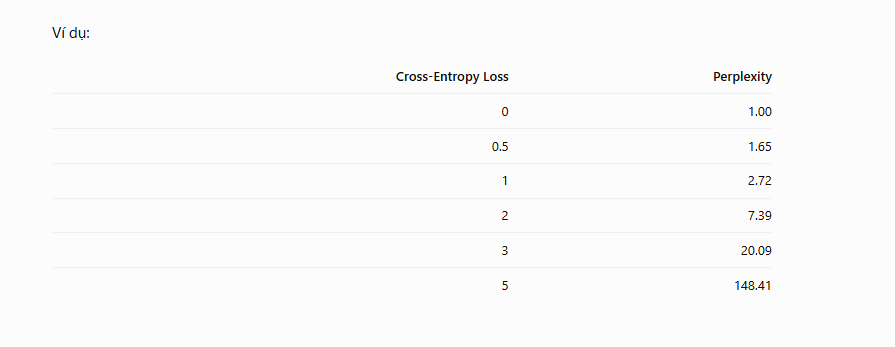
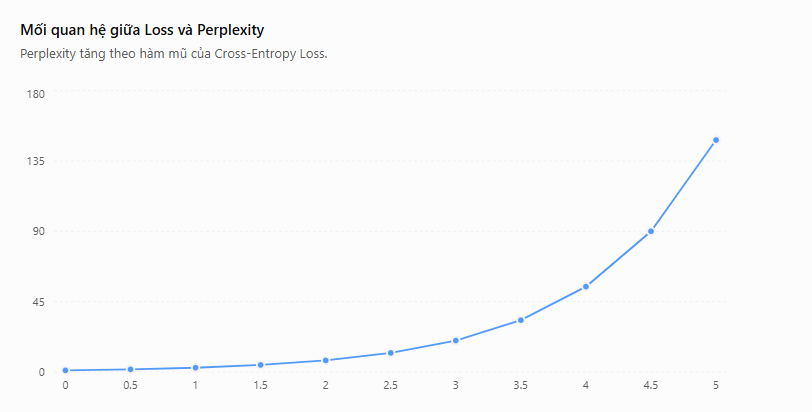

Hiểu Perplexity như thế nào?
Giả sử mô hình có Perplexity = 10.

Bạn có thể hình dung rằng, trung bình theo nghĩa xác suất hình học, mô hình có mức độ không chắc chắn tương đương việc phải lựa chọn giữa khoảng 10 khả năng ngang nhau tại mỗi bước dự đoán token.

Không có nghĩa là GPT chỉ xem xét đúng 10 token.

In [3]:
import torch

loss = torch.tensor(2.0)

ppl = torch.exp(loss)

print(ppl.item())
# 7.389...

7.389056205749512


Perplexity càng thấp thường càng tốt, nhưng chỉ nên so sánh trực tiếp khi dùng cùng tập đánh giá và cách tokenization tương thích.
Cross-Entropy và Perplexity khác nhau ở đâu?
Cross-Entropy là hàm loss thường dùng để huấn luyện GPT. Perplexity là cách diễn đạt lại loss để đánh giá mô hình ngôn ngữ.

Trong trường hợp dùng cùng Cross-Entropy trung bình, hai giá trị mang cùng thông tin vì:
$$
PPL=e^{Loss}
$$

### Forward, Backward, Optimizer

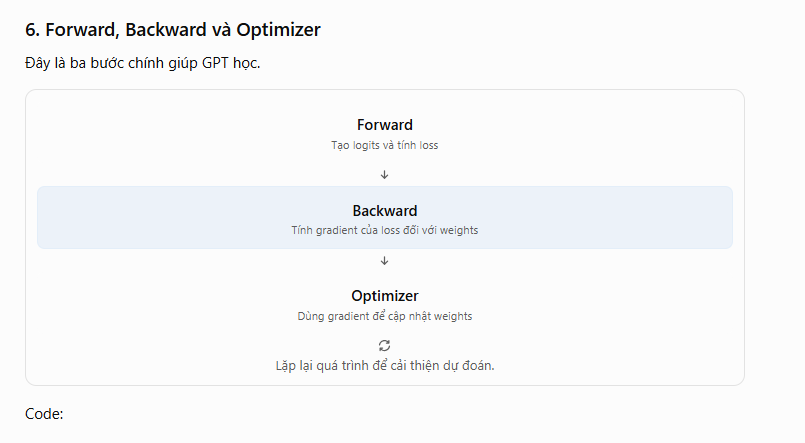

In [ ]:
optimizer.zero_grad()

logits = model(input_ids)

loss = F.cross_entropy(
    logits.flatten(0, 1),
    target_ids.flatten()
)

loss.backward()

optimizer.step()

Trong đó:
- zero_grad(): Xóa gradient tích lũy từ bước trước.
- forward: GPT tính logits.
- loss: Tính mức độ dự đoán sai.
- backward(): Tính gradient.
- step(): Optimizer cập nhật weights.

### 7. Gradient là gì?
Gradient cho biết loss thay đổi như thế nào khi weight thay đổi.  
Ví dụ đơn giản:
$$
L=(w-3)^2
$$

Gradient:
$$
\frac{dL}{dw}=2(w-3)
$$

Nếu w = 1:
$$
Gradient=-4
$$

Với learning rate 0.1, Gradient Descent cơ bản cập nhật:
$$
w_{\text{new}}=1-0.1(-4)=1.4
$$

Weight tiến gần đến giá trị 3, nơi loss nhỏ nhất.

Trong GPT, có hàng triệu weights, nên PyTorch dùng Autograd để tính gradient tự động.

### 8. Optimizer và Learning Rate
Optimizer là thuật toán cập nhật weights nhằm giảm loss.

GPT thường sử dụng AdamW:

In [ ]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0004,
    weight_decay=0.1
)

learning_rate quyết định quy mô bước cập nhật.
Learning rate	Có thể xảy ra
Quá lớn	Training dao động hoặc mất ổn định
Quá nhỏ	Học rất chậm
Phù hợp	Loss giảm tương đối ổn định
AdamW không đơn giản chỉ lấy weight - lr × gradient; nó còn sử dụng các thống kê gradient và weight decay.

10. Training Loss và Validation Loss
Khi huấn luyện, không nên chỉ nhìn Training Loss.

Training Loss: Loss trên dữ liệu mà mô hình đang học.

Validation Loss: Loss trên dữ liệu tách riêng, không dùng để cập nhật weights.
Hiện tượng	Diễn giải
Train Loss giảm, Val Loss giảm	Mô hình đang cải thiện trên cả hai tập
Train Loss giảm, Val Loss tăng	Có thể đang overfitting
Cả hai Loss đều cao	Mô hình có thể chưa học đủ hoặc cấu hình chưa phù hợp

### 11. Greedy Decoding, Temperature và Top-k
- Greedy Decoding
Luôn chọn token có logit cao nhất.
- Temperature
Temperature điều chỉnh phân phối xác suất.
   - Temperature thấp: Tập trung vào token có xác suất cao.
   - Temperature cao: Các token ít khả năng có cơ hội được chọn hơn.
- Top-k Sampling
Chỉ giữ k token có logits cao nhất

### 12. Saving Weights và Pretrained Weights
Khi GPT đã học, những gì nó học được chủ yếu được lưu trong weights.
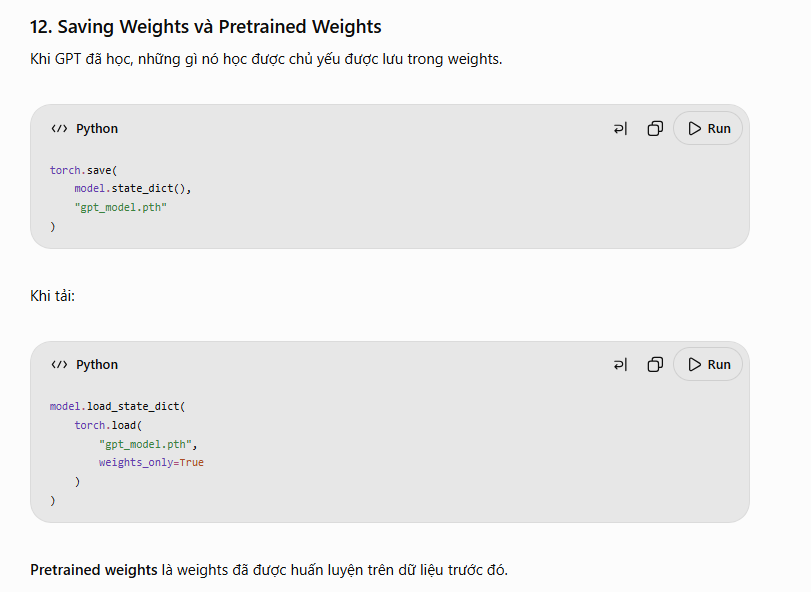

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)

# 1. Dữ liệu token IDs giả định
tokens = torch.tensor([
    0, 1, 2, 3, 0, 1, 2, 3,
    0, 1, 2, 3, 0, 1, 2, 3
])

# 2. Input và Target
x = tokens[:-1]
y = tokens[1:]

# 3. Mô hình dự đoán token tiếp theo
model = nn.Sequential(
    nn.Embedding(4, 8),
    nn.Linear(8, 4)
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.05
)

# 4. Training
for epoch in range(101):
    optimizer.zero_grad()

    logits = model(x)

    loss = F.cross_entropy(logits, y)

    loss.backward()
    optimizer.step()

    if epoch % 20 == 0:
        ppl = torch.exp(loss)

        print(
            f"Epoch {epoch} | "
            f"Loss: {loss.item():.4f} | "
            f"PPL: {ppl.item():.4f}"
        )

# 5. Dự đoán
model.eval()

with torch.no_grad():
    input_token = torch.tensor([0])

    logits = model(input_token)

    probs = torch.softmax(logits, dim=-1)

    next_token = torch.argmax(probs, dim=-1)

print("Next token:", next_token.item())

Epoch 0 | Loss: 1.7623 | PPL: 5.8261
Epoch 20 | Loss: 0.0020 | PPL: 1.0020
Epoch 40 | Loss: 0.0002 | PPL: 1.0002
Epoch 60 | Loss: 0.0002 | PPL: 1.0002
Epoch 80 | Loss: 0.0002 | PPL: 1.0002
Epoch 100 | Loss: 0.0002 | PPL: 1.0002
Next token: 1


IndentationError: unindent does not match any outer indentation level (<string>, line 6)